# Day 1: Fruit Freshness Classifier (Training + Evaluation)
**Project:** Food Quality & Waste Reduction using Deep Learning
**SDGs:** SDG 2 (Zero Hunger), SDG 13 (Climate Action), SDG 3 (Good Health and Well-being)

### Overview
- A **MobileNetV2** model (transfer learning, PyTorch) that classifies 6 classes: fresh/rotten × apple/banana/orange
- Test-set **accuracy, precision, recall, F1 and confusion matrix**
- All figures and metrics saved to Google Drive
- A saved model file (`best_mobilenetv2.pt`) used by the Day 2 demo app

**Environment:** Google Colab with a T4 GPU runtime. Cells run top to bottom, since later cells depend on earlier ones.

## Step 1: Imports, random seed, GPU check
**What:** loads the libraries, fixes the random seed and checks that the GPU is on.
**Why:** a fixed seed (`42`) makes results *reproducible*: re-running gives the same data split and very similar numbers.

In [1]:
import os, json, random, time, copy
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

SEED = 42
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device :", device)
if device.type == "cuda":
    print("GPU    :", torch.cuda.get_device_name(0))
else:
    print("\n⚠️  NO GPU! Go to Runtime -> Change runtime type -> T4 GPU, then re-run this cell.")

PyTorch: 2.14.1+cu130
Device : cuda
GPU    : Tesla T4


## Step 2: Connect Google Drive
**What:** every figure, metric and model file is saved to `MyDrive/fruit_freshness_project/`.
**Why:** Colab sessions can disconnect, and saving to Drive keeps the trained model and results safe.

In [2]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
    OUT = Path('/content/drive/MyDrive/fruit_freshness_project')
except Exception:
    # Not on Colab (e.g. Kaggle / local) - save next to the notebook instead
    OUT = Path('fruit_freshness_project')

FIG = OUT / 'figures'; RES = OUT / 'results'; MOD = OUT / 'models'
for d in (FIG, RES, MOD):
    d.mkdir(parents=True, exist_ok=True)
print("Saving everything to:", OUT.resolve())

Mounted at /content/drive
Saving everything to: /content/drive/MyDrive/fruit_freshness_project


## Step 3: Download the dataset
**Dataset:** *Fruits fresh and rotten for classification* (Kaggle, by Sriram Reddy Kalluri)
Six classes: `freshapples, freshbanana, freshoranges, rottenapples, rottenbanana, rottenoranges`, already split into `train/` and `test/` folders.

In [3]:
!pip install -q kagglehub
import kagglehub

DATA_ROOT = kagglehub.dataset_download("sriramr/fruits-fresh-and-rotten-for-classification")
print("Downloaded to:", DATA_ROOT)

Downloaded to: /kaggle/input/fruits-fresh-and-rotten-for-classification


In [4]:
# Find the train/ and test/ folders automatically (the zip has nested folders)
def find_split_dir(root, split_name):
    for dirpath, dirnames, _ in os.walk(root):
        if Path(dirpath).name.lower() == split_name:
            subs = [d.lower() for d in dirnames]
            if sum(('fresh' in d) or ('rotten' in d) for d in subs) >= 4:
                return Path(dirpath)
    return None

TRAIN_DIR = find_split_dir(DATA_ROOT, "train")
TEST_DIR  = find_split_dir(DATA_ROOT, "test")
print("TRAIN_DIR:", TRAIN_DIR)
print("TEST_DIR :", TEST_DIR)

if TRAIN_DIR is None:
    # Print the folder tree so you can set TRAIN_DIR manually
    for dirpath, dirnames, filenames in os.walk(DATA_ROOT):
        depth = len(Path(dirpath).relative_to(DATA_ROOT).parts)
        if depth <= 3:
            print("  " * depth + Path(dirpath).name + f"/  ({len(filenames)} files)")
    raise RuntimeError("Could not find train folder - look at the tree above and set TRAIN_DIR = Path('...') manually")

TRAIN_DIR: /kaggle/input/fruits-fresh-and-rotten-for-classification/dataset/dataset/train
TEST_DIR : /kaggle/input/fruits-fresh-and-rotten-for-classification/dataset/dataset/test


## Step 4: Data cleaning (remove corrupt / non-image files)
**What:** opens every file once and skips any that are broken or aren't images.
**Why:** one corrupt image can crash training halfway, so broken files are removed up front and the number removed is reported.

In [5]:
IMG_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}

def scan_bad_files(folder):
    bad = set()
    if folder is None:
        return bad
    for p in Path(folder).rglob('*'):
        if not p.is_file():
            continue
        if p.suffix.lower() not in IMG_EXT:
            bad.add(str(p.resolve())); continue
        try:
            with Image.open(p) as im:
                im.verify()
        except Exception:
            bad.add(str(p.resolve()))
    return bad

t0 = time.time()
BAD = scan_bad_files(TRAIN_DIR) | scan_bad_files(TEST_DIR)
print(f"Scan done in {time.time()-t0:.0f}s. Bad / non-image files skipped: {len(BAD)}")
for b in list(BAD)[:10]:
    print("  ", b)

def is_good_image(path):
    return Path(path).suffix.lower() in IMG_EXT and str(Path(path).resolve()) not in BAD

Scan done in 135s. Bad / non-image files skipped: 0


## Step 5: Explore the data (EDA)
**What:** counts images per class, shows sample images and checks image sizes.
**Why:** confirms how many images and classes there are and whether the classes are balanced.

               train_folder  test_folder
freshapples            1693          395
freshbanana            1581          381
freshoranges           1466          388
rottenapples           2342          601
rottenbanana           2224          530
rottenoranges          1595          403
TOTAL                 10901         2698


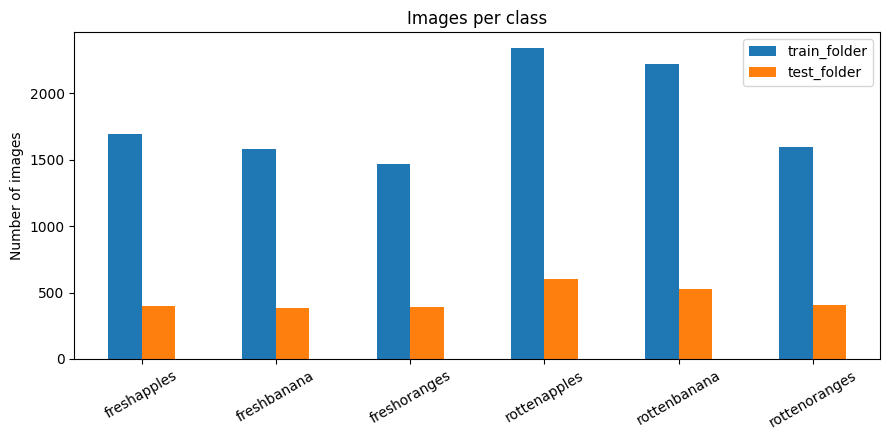

In [6]:
def count_per_class(folder):
    counts = {}
    if folder is None:
        return counts
    for c in sorted(os.listdir(folder)):
        d = Path(folder) / c
        if d.is_dir():
            counts[c] = sum(1 for p in d.rglob('*') if p.is_file() and is_good_image(p))
    return counts

train_counts = count_per_class(TRAIN_DIR)
test_counts  = count_per_class(TEST_DIR)
count_df = pd.DataFrame({'train_folder': train_counts, 'test_folder': pd.Series(test_counts)}).fillna(0).astype(int)
count_df.loc['TOTAL'] = count_df.sum()
print(count_df)
count_df.to_csv(RES / 'class_counts.csv')

# Bar chart
plot_df = count_df.drop('TOTAL')
ax = plot_df.plot(kind='bar', figsize=(9, 4.5), rot=30)
ax.set_title('Images per class'); ax.set_ylabel('Number of images'); ax.set_xlabel('')
plt.tight_layout(); plt.savefig(FIG / 'class_distribution.png', dpi=200); plt.show()

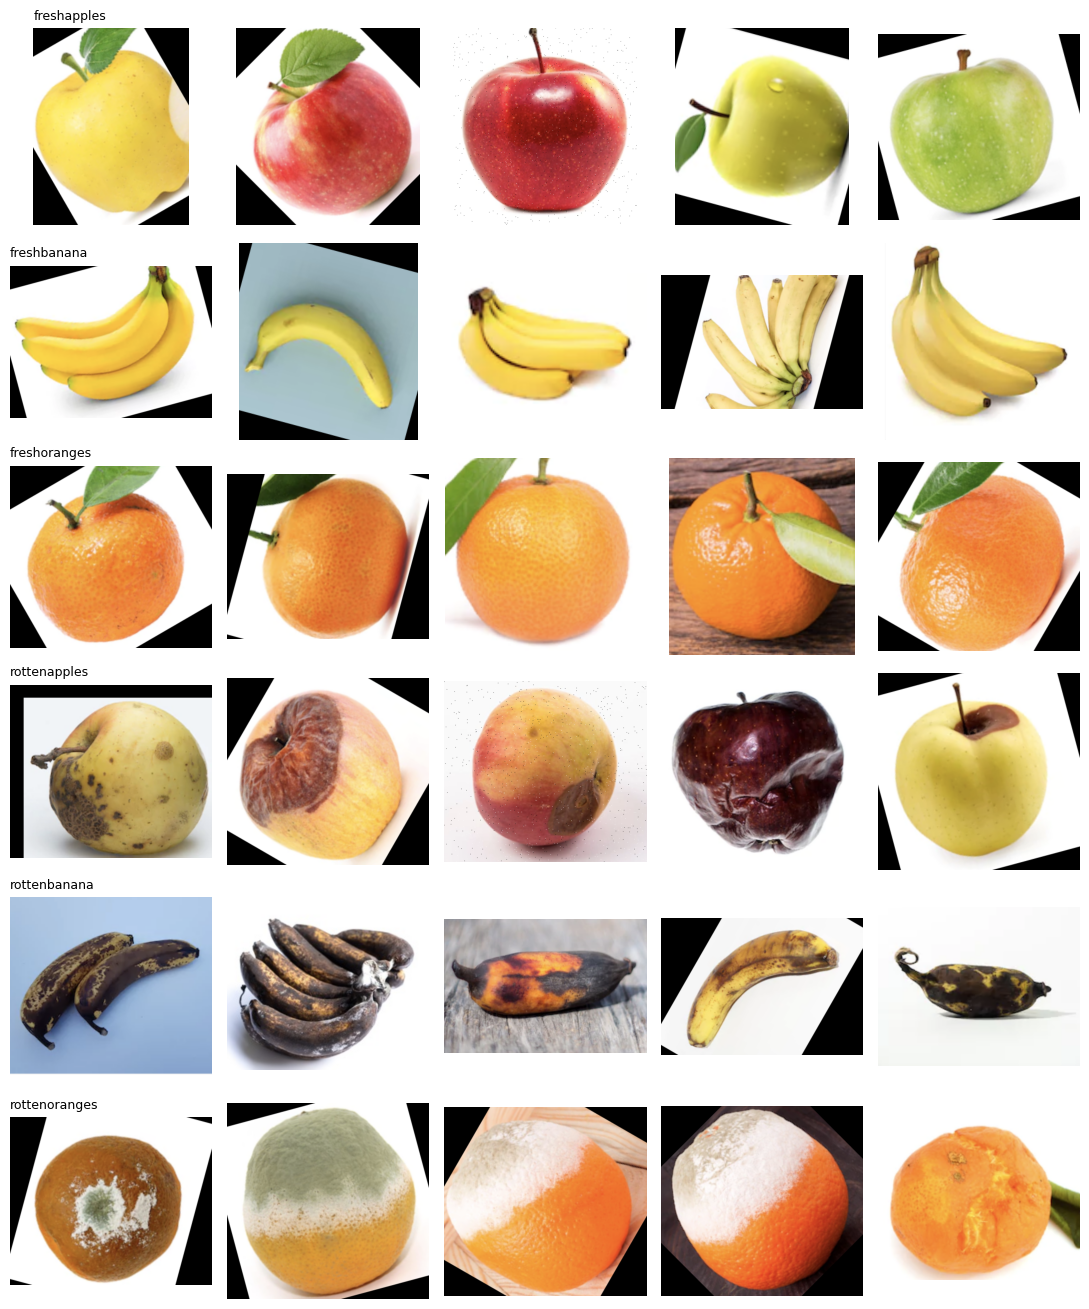

Width : min 164, median 398, max 774
Height: min 154, median 359, max 518
-> Images have different sizes, so we resize everything to 224x224 (the size MobileNetV2 expects).


In [7]:
# Sample images: 5 random images per class
classes = sorted(train_counts.keys())
n_show = 5
fig, axes = plt.subplots(len(classes), n_show, figsize=(n_show * 2.2, len(classes) * 2.2))
for r, c in enumerate(classes):
    files = [p for p in (Path(TRAIN_DIR) / c).rglob('*') if p.is_file() and is_good_image(p)]
    for k, p in enumerate(random.sample(files, min(n_show, len(files)))):
        axes[r, k].imshow(Image.open(p).convert('RGB'))
        axes[r, k].axis('off')
    axes[r, 0].set_title(c, fontsize=9, loc='left')
for a in axes.flat:
    a.axis('off')
plt.tight_layout(); plt.savefig(FIG / 'sample_images.png', dpi=200); plt.show()

# Image size statistics (sample of 300)
all_files = [p for p in Path(TRAIN_DIR).rglob('*') if p.is_file() and is_good_image(p)]
sizes = np.array([Image.open(p).size for p in random.sample(all_files, min(300, len(all_files)))])
print(f"Width : min {sizes[:,0].min()}, median {int(np.median(sizes[:,0]))}, max {sizes[:,0].max()}")
print(f"Height: min {sizes[:,1].min()}, median {int(np.median(sizes[:,1]))}, max {sizes[:,1].max()}")
print("-> Images have different sizes, so we resize everything to 224x224 (the size MobileNetV2 expects).")

## Step 6: Preprocessing and data augmentation
**What each transform does, and why:**

| Transform | Used on | Why |
|---|---|---|
| `RandomResizedCrop(224, scale=0.7–1.0)` | train | Random zoom/crop, so the model doesn't rely on the fruit always being centred |
| `RandomHorizontalFlip` | train | A flipped apple is still an apple |
| `RandomRotation(15°)` | train | Handles tilted photos |
| `ColorJitter(brightness, contrast)` | train | Handles different lighting (e.g. shop vs kitchen) |
| `Resize(256) + CenterCrop(224)` | val / test | Deterministic, so every evaluation is the same |
| `Normalize(ImageNet mean/std)` | all | The pretrained MobileNetV2 was trained on ImageNet-normalised images |

**Design choice:** we deliberately **do not jitter hue or saturation**. Colour change (browning, dark spots, dullness) is exactly *how* rotting shows up, so randomly changing colours would destroy the signal the model needs.

Augmentation is applied **only to training data**, never to validation/test, because evaluation must reflect real, unmodified images.

In [11]:
IMG_SIZE = 224
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_tf = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

## Step 7: Train / validation / test split
**What:**
- `train/` folder → split **85% train, 15% validation** (stratified: same class ratio in both).
- `test/` folder → kept completely separate and used **only once** at the end.

**Why:**
- *Validation* is used to choose the best epoch and tune settings.
- *Test* is never seen during training or tuning, so the final numbers are an honest estimate. Tuning on the test set would inflate accuracy (data leakage).
- *Stratified* means rare classes aren't accidentally missing from validation.

In [12]:
full_train_aug  = datasets.ImageFolder(TRAIN_DIR, transform=train_tf, is_valid_file=is_good_image)
full_train_eval = datasets.ImageFolder(TRAIN_DIR, transform=eval_tf,  is_valid_file=is_good_image)
CLASS_NAMES = full_train_aug.classes
NUM_CLASSES = len(CLASS_NAMES)
print("Classes:", CLASS_NAMES)

targets = np.array(full_train_aug.targets)
all_idx = np.arange(len(targets))

test_ds = None
if TEST_DIR is not None:
    test_ds = datasets.ImageFolder(TEST_DIR, transform=eval_tf, is_valid_file=is_good_image)
    if test_ds.classes != CLASS_NAMES:
        print("⚠️ test/ class names don't match train/ - will make our own test split instead.")
        test_ds = None

if test_ds is not None:
    train_idx, val_idx = train_test_split(all_idx, test_size=0.15, stratify=targets, random_state=SEED)
else:
    # Fallback: 70 / 15 / 15 split of the train folder
    train_idx, tmp_idx = train_test_split(all_idx, test_size=0.30, stratify=targets, random_state=SEED)
    val_idx, test_idx  = train_test_split(tmp_idx, test_size=0.50, stratify=targets[tmp_idx], random_state=SEED)
    test_ds = Subset(full_train_eval, test_idx)

train_ds = Subset(full_train_aug, train_idx)
val_ds   = Subset(full_train_eval, val_idx)

BATCH_SIZE = 32
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

split_sizes = {'train': len(train_ds), 'validation': len(val_ds), 'test': len(test_ds)}
print("Split sizes:", split_sizes)
json.dump({'classes': CLASS_NAMES, 'split_sizes': split_sizes}, open(RES / 'split_info.json', 'w'), indent=2)

Classes: ['freshapples', 'freshbanana', 'freshoranges', 'rottenapples', 'rottenbanana', 'rottenoranges']
Split sizes: {'train': 9265, 'validation': 1636, 'test': 2698}


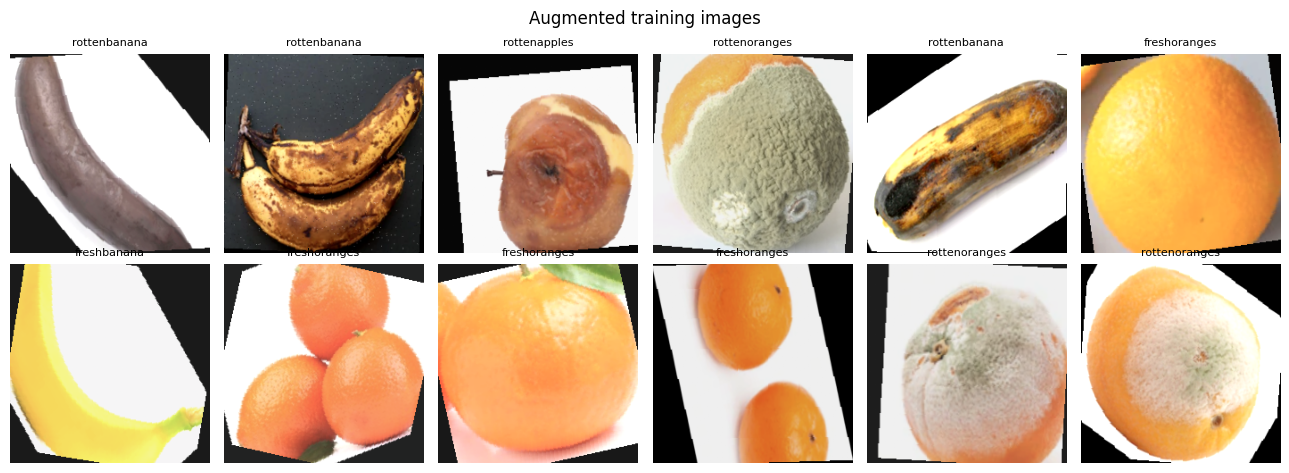

In [13]:
# Look at one augmented training batch
def denorm(t):
    t = t.cpu() * torch.tensor(STD).view(3, 1, 1) + torch.tensor(MEAN).view(3, 1, 1)
    return t.clamp(0, 1).permute(1, 2, 0).numpy()

xb, yb = next(iter(train_loader))
fig, axes = plt.subplots(2, 6, figsize=(13, 4.8))
for a, x, y in zip(axes.flat, xb, yb):
    a.imshow(denorm(x)); a.set_title(CLASS_NAMES[y], fontsize=8); a.axis('off')
plt.suptitle('Augmented training images'); plt.tight_layout()
plt.savefig(FIG / 'augmentation_examples.png', dpi=200); plt.show()

## Step 8: Build the model (MobileNetV2 with transfer learning)
**Architecture:**
- **Backbone:** MobileNetV2 pretrained on ImageNet (1.2M images, 1000 classes). It already knows edges, textures and colours.
- Built from *inverted residual blocks* with *depthwise-separable convolutions*, so it's very light (~2.2M parameters vs ~138M for VGG16).
- **New head:** `Dropout(0.3) → Linear(1280 → 6)`. The original 1000-class layer is replaced with our 6 classes.

**Why MobileNetV2:**
1. **Transfer learning:** we have only ~10k training images (exact count in Step 5), too few to train a big CNN from scratch well. Pretrained features give high accuracy fast.
2. **Lightweight:** small enough to run on a phone or cheap device at a market, warehouse or food bank. That's the real-world SDG 2 use case.
3. **Fast to train** on a free Colab GPU.

In [14]:
def build_mobilenet(num_classes):
    model = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V1)
    for p in model.features.parameters():        # freeze the pretrained backbone
        p.requires_grad = False
    in_features = model.classifier[1].in_features  # 1280
    model.classifier = nn.Sequential(
        nn.Dropout(0.3),
        nn.Linear(in_features, num_classes),
    )
    return model

def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

model = build_mobilenet(NUM_CLASSES).to(device)
total, trainable = count_params(model)
print(f"Total parameters    : {total:,}")
print(f"Trainable (phase 1) : {trainable:,}  <- only the new head")

Total parameters    : 2,231,558
Trainable (phase 1) : 7,686  <- only the new head


## Step 9: Training functions
**What:**
- **Loss:** Cross-Entropy (standard for multi-class classification).
- **Optimizer:** Adam.
- **Checkpointing:** after every epoch we check validation loss. If it's the best so far, we save the model to Drive.
- **Early stopping:** if validation loss doesn't improve for 3 epochs, training stops (prevents overfitting and saves time).

In [15]:
criterion = nn.CrossEntropyLoss()

def run_epoch(model, loader, optimizer=None, backbone_frozen=False):
    training = optimizer is not None
    model.train(training)
    if training and backbone_frozen and hasattr(model, 'features'):
        model.features.eval()   # keep frozen BatchNorm statistics fixed
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            out = model(x)
            loss = criterion(out, y)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n

def save_checkpoint(model, path, arch):
    torch.save({'arch': arch, 'model_state': model.state_dict(), 'class_names': CLASS_NAMES,
                'img_size': IMG_SIZE, 'mean': MEAN, 'std': STD}, path)

def fit(model, optimizer, epochs, phase, history, best, ckpt_path, arch,
        scheduler=None, patience=3, backbone_frozen=False):
    bad_epochs = 0
    for ep in range(1, epochs + 1):
        t0 = time.time()
        tr_loss, tr_acc = run_epoch(model, train_loader, optimizer, backbone_frozen)
        va_loss, va_acc = run_epoch(model, val_loader)
        if scheduler is not None:
            scheduler.step(va_loss)
        history.append(dict(phase=phase, epoch=len(history) + 1, train_loss=tr_loss, train_acc=tr_acc,
                            val_loss=va_loss, val_acc=va_acc, lr=optimizer.param_groups[0]['lr'],
                            seconds=round(time.time() - t0, 1)))
        flag = ''
        if va_loss < best['val_loss']:
            best.update(val_loss=va_loss, val_acc=va_acc, state=copy.deepcopy(model.state_dict()))
            save_checkpoint(model, ckpt_path, arch)
            bad_epochs, flag = 0, '  ✓ saved'
        else:
            bad_epochs += 1
        print(f"[{phase}] epoch {ep}/{epochs} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
              f"val loss {va_loss:.4f} acc {va_acc:.4f} | {time.time()-t0:.0f}s{flag}")
        if bad_epochs >= patience:
            print(f"Early stopping: no val-loss improvement for {patience} epochs.")
            break

## Step 10: Train in two phases
**Phase 1, feature extraction (4 epochs, lr = 1e-3):** the backbone is frozen and only the new head learns. It's fast and stable.

**Phase 2, fine-tuning (up to 8 epochs, lr = 1e-4):** we unfreeze the **last 4 inverted-residual blocks + the final conv layer** of MobileNetV2 (`features[14:]`) so the high-level features adapt to fruit textures (bruises, mould, wrinkles). We use a **10× smaller learning rate** so we don't destroy the pretrained knowledge. `ReduceLROnPlateau` lowers the LR further if validation loss stalls.

**Why two phases:** if everything is unfrozen at the start, the randomly initialised head sends large, noisy gradients into the pretrained layers and damages them. Training the head first, then gently fine-tuning, is the standard transfer-learning recipe.

In [16]:
CKPT = MOD / 'best_mobilenetv2.pt'
history, best = [], {'val_loss': float('inf')}
t_start = time.time()

# ---------- Phase 1: train only the head ----------
EPOCHS_P1, LR_P1 = 4, 1e-3
opt1 = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=LR_P1)
fit(model, opt1, EPOCHS_P1, 'phase1', history, best, CKPT, 'mobilenet_v2', backbone_frozen=True)

[phase1] epoch 1/4 | train loss 0.2402 acc 0.9356 | val loss 0.0863 acc 0.9786 | 89s  ✓ saved
[phase1] epoch 2/4 | train loss 0.0847 acc 0.9755 | val loss 0.0559 acc 0.9847 | 83s  ✓ saved
[phase1] epoch 3/4 | train loss 0.0660 acc 0.9799 | val loss 0.0438 acc 0.9902 | 81s  ✓ saved
[phase1] epoch 4/4 | train loss 0.0517 acc 0.9842 | val loss 0.0400 acc 0.9884 | 83s  ✓ saved


In [17]:
# ---------- Phase 2: fine-tune the top of the backbone ----------
model.load_state_dict(best['state'])            # continue from the best phase-1 weights
UNFREEZE_FROM = 14                              # features[14:] = last 4 inverted-residual blocks + final 1x1 conv
for p in model.features[UNFREEZE_FROM:].parameters():
    p.requires_grad = True
print(f"Trainable parameters now: {count_params(model)[1]:,}")

EPOCHS_P2, LR_P2 = 8, 1e-4
opt2 = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=LR_P2)
sched2 = torch.optim.lr_scheduler.ReduceLROnPlateau(opt2, mode='min', factor=0.3, patience=1)
fit(model, opt2, EPOCHS_P2, 'phase2', history, best, CKPT, 'mobilenet_v2', scheduler=sched2, patience=3)

model.load_state_dict(best['state'])            # keep the best epoch, not the last one
mobilenet_train_minutes = (time.time() - t_start) / 60
print(f"\nTotal training time: {mobilenet_train_minutes:.1f} min | best val acc {best['val_acc']:.4f}")

hist_df = pd.DataFrame(history)
hist_df.to_csv(RES / 'training_history.csv', index=False)

hyperparams = dict(model='MobileNetV2 (ImageNet pretrained)', img_size=IMG_SIZE, batch_size=BATCH_SIZE,
                   optimizer='Adam', loss='CrossEntropy', phase1=dict(epochs=EPOCHS_P1, lr=LR_P1, trainable='head only'),
                   phase2=dict(max_epochs=EPOCHS_P2, lr=LR_P2, trainable=f'features[{UNFREEZE_FROM}:] + head',
                               scheduler='ReduceLROnPlateau(factor=0.3, patience=1)'),
                   early_stopping_patience=3, dropout=0.3, seed=SEED, val_split=0.15,
                   train_minutes=round(mobilenet_train_minutes, 1))
json.dump(hyperparams, open(RES / 'hyperparameters.json', 'w'), indent=2)
print(json.dumps(hyperparams, indent=2))

Trainable parameters now: 1,689,030
[phase2] epoch 1/8 | train loss 0.0831 acc 0.9725 | val loss 0.0160 acc 0.9951 | 82s  ✓ saved
[phase2] epoch 2/8 | train loss 0.0276 acc 0.9893 | val loss 0.0253 acc 0.9908 | 83s
[phase2] epoch 3/8 | train loss 0.0240 acc 0.9911 | val loss 0.0284 acc 0.9884 | 85s
[phase2] epoch 4/8 | train loss 0.0099 acc 0.9968 | val loss 0.0020 acc 0.9994 | 89s  ✓ saved
[phase2] epoch 5/8 | train loss 0.0082 acc 0.9976 | val loss 0.0086 acc 0.9969 | 86s
[phase2] epoch 6/8 | train loss 0.0062 acc 0.9983 | val loss 0.0015 acc 0.9994 | 84s  ✓ saved
[phase2] epoch 7/8 | train loss 0.0033 acc 0.9992 | val loss 0.0009 acc 1.0000 | 84s  ✓ saved
[phase2] epoch 8/8 | train loss 0.0052 acc 0.9982 | val loss 0.0016 acc 1.0000 | 84s

Total training time: 17.2 min | best val acc 1.0000
{
  "model": "MobileNetV2 (ImageNet pretrained)",
  "img_size": 224,
  "batch_size": 32,
  "optimizer": "Adam",
  "loss": "CrossEntropy",
  "phase1": {
    "epochs": 4,
    "lr": 0.001,
    "trai

## Step 11: Training curves
**What:** loss and accuracy per epoch for train vs validation. The dashed line marks where fine-tuning starts.
**How to read it:**
- Both curves going down/up together → the model is learning well.
- Train accuracy ≫ validation accuracy and validation loss rising → overfitting (early stopping protects against this).

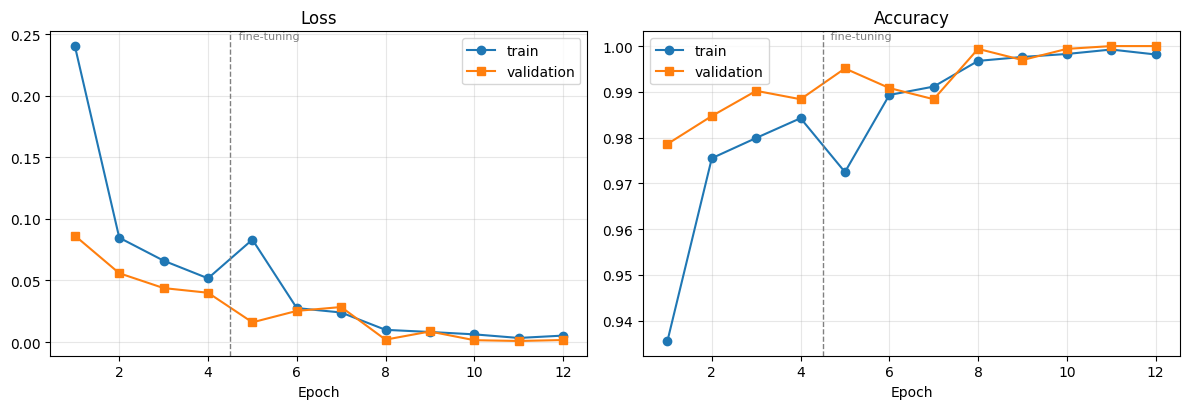

In [18]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.2))
e = hist_df['epoch']
a1.plot(e, hist_df['train_loss'], 'o-', label='train'); a1.plot(e, hist_df['val_loss'], 's-', label='validation')
a2.plot(e, hist_df['train_acc'], 'o-', label='train');  a2.plot(e, hist_df['val_acc'], 's-', label='validation')
p2_start = hist_df.loc[hist_df['phase'] == 'phase2', 'epoch'].min()
for a, t in ((a1, 'Loss'), (a2, 'Accuracy')):
    if not np.isnan(p2_start):
        a.axvline(p2_start - 0.5, ls='--', c='grey', lw=1); a.text(p2_start - 0.4, a.get_ylim()[1], ' fine-tuning', va='top', fontsize=8, color='grey')
    a.set_title(t); a.set_xlabel('Epoch'); a.legend(); a.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(FIG / 'training_curves.png', dpi=200); plt.show()

## Step 12: Final evaluation on the test set
**What:** we run the best model on the held-out test set **once** and compute:
- **Accuracy:** overall % correct
- **Precision** (per class): when the model says "rotten banana", how often is it right?
- **Recall** (per class): of all real rotten bananas, how many did it catch?
- **F1:** harmonic mean of precision and recall
- **Macro average:** treats every class equally, even if class sizes differ
- **Confusion matrix:** which classes get mixed up with which

**Fresh vs rotten metric:** we also collapse the 6 classes into 2 (fresh / rotten). In the real use case, the key question is *"is this safe to distribute?"*. **Recall on 'rotten'** matters most, because a rotten fruit predicted as fresh can reach a person (SDG 3 health risk).

               precision    recall  f1-score   support

  freshapples     0.9950    1.0000    0.9975       395
  freshbanana     1.0000    1.0000    1.0000       381
 freshoranges     1.0000    1.0000    1.0000       388
 rottenapples     1.0000    0.9967    0.9983       601
 rottenbanana     1.0000    1.0000    1.0000       530
rottenoranges     1.0000    1.0000    1.0000       403

     accuracy                         0.9993      2698
    macro avg     0.9992    0.9994    0.9993      2698
 weighted avg     0.9993    0.9993    0.9993      2698

model                     : MobileNetV2 (transfer learning)
test_accuracy             : 0.9993
macro_precision           : 0.9992
macro_recall              : 0.9994
macro_f1                  : 0.9993
fresh_vs_rotten_accuracy  : 0.9993
rotten_precision          : 1.0000
rotten_recall             : 0.9987
rotten_f1                 : 0.9993
n_test_images             : 2698


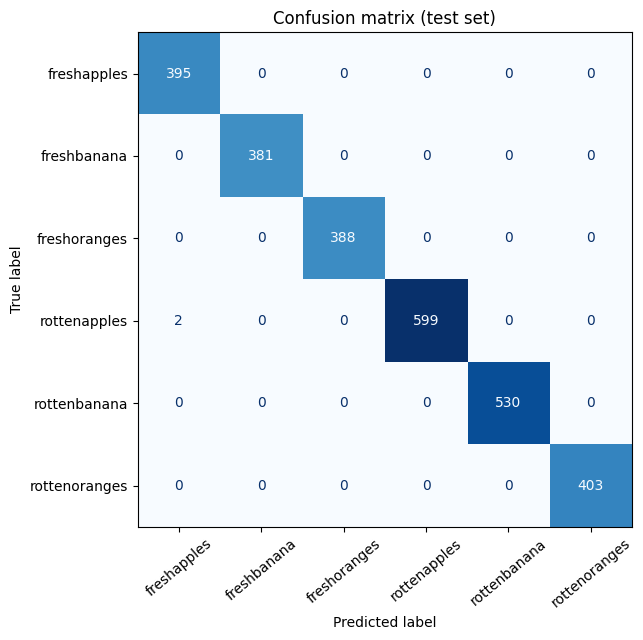

In [19]:
@torch.no_grad()
def predict_loader(model, loader):
    model.eval()
    ys, ps, probs = [], [], []
    for x, y in loader:
        pr = model(x.to(device)).softmax(1).cpu()
        probs.append(pr); ps.append(pr.argmax(1)); ys.append(y)
    return torch.cat(ys).numpy(), torch.cat(ps).numpy(), torch.cat(probs).numpy()

def evaluate(model, name):
    y_true, y_pred, y_prob = predict_loader(model, test_loader)
    acc = accuracy_score(y_true, y_pred)
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='macro', zero_division=0)
    # Collapse to fresh(0) / rotten(1)
    is_rotten = np.array(['rotten' in c.lower() for c in CLASS_NAMES]).astype(int)
    bt, bp = is_rotten[y_true], is_rotten[y_pred]
    bin_p, bin_r, bin_f1, _ = precision_recall_fscore_support(bt, bp, average='binary', pos_label=1, zero_division=0)
    metrics = {'model': name, 'test_accuracy': acc, 'macro_precision': p, 'macro_recall': r, 'macro_f1': f1,
               'fresh_vs_rotten_accuracy': accuracy_score(bt, bp), 'rotten_precision': bin_p,
               'rotten_recall': bin_r, 'rotten_f1': bin_f1, 'n_test_images': int(len(y_true))}
    return metrics, y_true, y_pred, y_prob

metrics, y_true, y_pred, y_prob = evaluate(model, 'MobileNetV2 (transfer learning)')
report_txt = classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4, zero_division=0)

print(report_txt)
for k, v in metrics.items():
    print(f"{k:26s}: {v:.4f}" if isinstance(v, float) else f"{k:26s}: {v}")

(RES / 'classification_report.txt').write_text(report_txt)
json.dump({k: (round(v, 4) if isinstance(v, float) else v) for k, v in metrics.items()},
          open(RES / 'test_metrics.json', 'w'), indent=2)

cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(7.5, 6.5))
ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(ax=ax, cmap='Blues', xticks_rotation=40, colorbar=False, values_format='d')
ax.set_title('Confusion matrix (test set)')
plt.tight_layout(); plt.savefig(FIG / 'confusion_matrix.png', dpi=200); plt.show()

## Step 13: Look at the mistakes
**What:** shows test images the model got wrong.
**Why:** reveals patterns in the errors, e.g. slightly bruised apples predicted as fresh, or dark lighting confusing the model.

Misclassified: 2 / 2698 test images


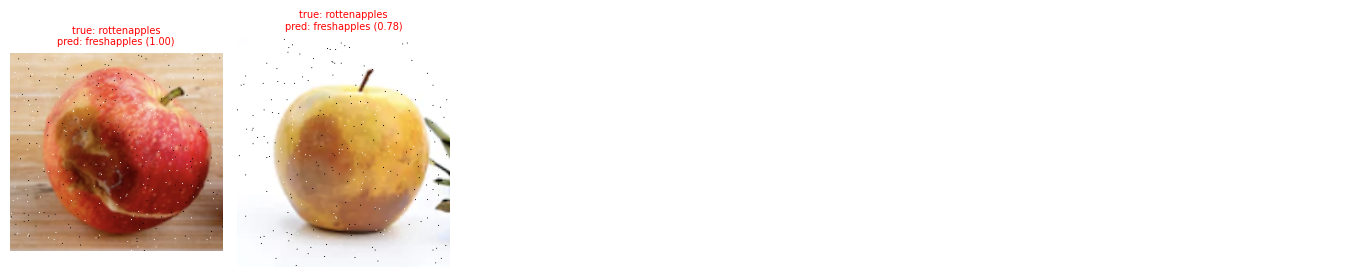

In [20]:
def dataset_paths(ds):
    if isinstance(ds, Subset):
        return [ds.dataset.samples[i][0] for i in ds.indices]
    return [s[0] for s in ds.samples]

test_paths = dataset_paths(test_ds)
wrong = np.where(y_true != y_pred)[0]
print(f"Misclassified: {len(wrong)} / {len(y_true)} test images")

if len(wrong):
    show = wrong[:12]
    cols = 6; rows = int(np.ceil(len(show) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 2.3, rows * 2.7))
    axes = np.array(axes).reshape(-1)
    for a in axes: a.axis('off')
    for a, i in zip(axes, show):
        a.imshow(Image.open(test_paths[i]).convert('RGB'))
        a.set_title(f"true: {CLASS_NAMES[y_true[i]]}\npred: {CLASS_NAMES[y_pred[i]]} ({y_prob[i].max():.2f})", fontsize=7, color='red')
    plt.tight_layout(); plt.savefig(FIG / 'misclassified_examples.png', dpi=200); plt.show()
else:
    print("No mistakes on the test set.")

## Step 14: Predict a single image
**What:** the full input → preprocessing → prediction → output pipeline, run on a random test image.

Image : /kaggle/input/fruits-fresh-and-rotten-for-classification/dataset/dataset/test/freshoranges/saltandpepper_Screen Shot 2018-06-13 at 12.10.53 AM.png
Truth : freshoranges
Pred  : [('freshoranges', 1.0), ('freshapples', 0.0), ('rottenoranges', 0.0)]


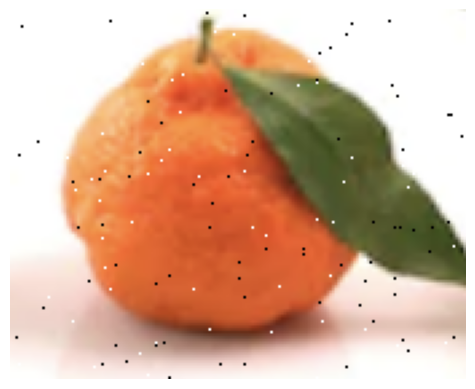

In [21]:
@torch.no_grad()
def predict_image(model, img, top_k=3):
    if not isinstance(img, Image.Image):
        img = Image.open(img)
    x = eval_tf(img.convert('RGB')).unsqueeze(0).to(device)
    model.eval()
    probs = model(x).softmax(1)[0].cpu()
    top = probs.topk(top_k)
    return [(CLASS_NAMES[int(i)], round(float(p), 4)) for p, i in zip(top.values, top.indices)]

sample = random.choice(test_paths)
print("Image :", sample)
print("Truth :", Path(sample).parent.name)
print("Pred  :", predict_image(model, sample))
plt.imshow(Image.open(sample).convert('RGB')); plt.axis('off'); plt.show()

## Step 15: Baseline CNN from scratch, for comparison
**What:** a simple 4-block CNN trained from scratch on the same data, then compared with MobileNetV2.
**Why:** the comparison table (*Custom CNN vs MobileNetV2*) shows the benefit of transfer learning.

In [22]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        def block(i, o):
            return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(inplace=True), nn.MaxPool2d(2))
        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128), block(128, 256))
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(0.3), nn.Linear(256, num_classes))
    def forward(self, x):
        return self.head(self.pool(self.features(x)))

RUN_BASELINE = True   # set False to skip
if RUN_BASELINE:
    base = SimpleCNN(NUM_CLASSES).to(device)
    print(f"Baseline parameters: {count_params(base)[0]:,}")
    b_hist, b_best = [], {'val_loss': float('inf')}
    t0 = time.time()
    b_opt = torch.optim.Adam(base.parameters(), lr=1e-3)
    fit(base, b_opt, 8, 'baseline', b_hist, b_best, MOD / 'baseline_cnn.pt', 'simple_cnn', patience=3)
    base.load_state_dict(b_best['state'])
    base_minutes = (time.time() - t0) / 60
    b_metrics, *_ = evaluate(base, 'Custom CNN (from scratch)')

    rows = []
    for m, params, mins in ((metrics, count_params(model)[0], mobilenet_train_minutes),
                            (b_metrics, count_params(base)[0], base_minutes)):
        rows.append({'Model': m['model'], 'Parameters': f"{params:,}", 'Train time (min)': round(mins, 1),
                     'Test accuracy': round(m['test_accuracy'], 4), 'Macro F1': round(m['macro_f1'], 4),
                     'Rotten recall': round(m['rotten_recall'], 4)})
    comp = pd.DataFrame(rows)
    comp.to_csv(RES / 'model_comparison.csv', index=False)
    display(comp)

Baseline parameters: 390,918
[baseline] epoch 1/8 | train loss 0.6145 acc 0.7967 | val loss 0.4174 acc 0.8600 | 88s  ✓ saved
[baseline] epoch 2/8 | train loss 0.4233 acc 0.8536 | val loss 0.2787 acc 0.8973 | 88s  ✓ saved
[baseline] epoch 3/8 | train loss 0.3623 acc 0.8708 | val loss 0.3906 acc 0.8655 | 88s
[baseline] epoch 4/8 | train loss 0.3357 acc 0.8821 | val loss 0.2704 acc 0.8998 | 88s  ✓ saved
[baseline] epoch 5/8 | train loss 0.3077 acc 0.8910 | val loss 0.2516 acc 0.9108 | 88s  ✓ saved
[baseline] epoch 6/8 | train loss 0.2790 acc 0.9013 | val loss 0.2423 acc 0.9181 | 89s  ✓ saved
[baseline] epoch 7/8 | train loss 0.2654 acc 0.9034 | val loss 0.3846 acc 0.8521 | 93s
[baseline] epoch 8/8 | train loss 0.2390 acc 0.9151 | val loss 0.1878 acc 0.9352 | 87s  ✓ saved


,Model,Parameters,Train time (min),Test accuracy,Macro F1,Rotten recall
0,MobileNetV2 (transfer learning),"2,231,558",17.2,0.9993,0.9993,0.9987
1,Custom CNN (from scratch),"390,918",11.8,0.9396,0.9404,0.9544


## Saved outputs
All files are in `MyDrive/fruit_freshness_project/`.

| File | Contents |
|---|---|
| `figures/class_distribution.png`, `results/class_counts.csv` | Images per class |
| `figures/sample_images.png` | Sample images per class |
| `figures/augmentation_examples.png` | Augmented training images |
| `results/hyperparameters.json` | Training settings |
| `figures/training_curves.png`, `results/training_history.csv` | Loss and accuracy per epoch |
| `results/test_metrics.json`, `results/classification_report.txt` | Test-set metrics |
| `figures/confusion_matrix.png` | Confusion matrix |
| `figures/misclassified_examples.png` | Misclassified test images |
| `results/model_comparison.csv` | Custom CNN vs MobileNetV2 |
| `models/best_mobilenetv2.pt` | Trained model, used by the Day 2 notebook |